# Fil rouge ProtAnnotML · 2 — Découper sans tricher : splits par homologie

> **Objectif** : construire des partitions entraînement / validation / test qui mesurent ce que l'on prétend mesurer. On quantifie la **fuite par homologie** (des séquences de test quasi identiques à des séquences d'entraînement), on regroupe les germlines par identité, et on définit plusieurs **régimes d'évaluation** (nouvel anticorps, nouveau gène, nouvelle espèce) qui répondent chacun à une question différente.

| | |
|---|---|
| **Durée estimée** | 1 h 30 |
| **Prérequis** | Fil rouge 1 ; module 8 (fuite par similarité) |
| **Librairies** | `numpy`, `scipy`, `pandas`, `matplotlib` ; MMseqs2 pour les vraies données |

**Plan**

1. Pourquoi le découpage aléatoire ment
2. Identité de séquence sur des alignements IMGT
3. Regrouper les germlines : seuils et clusters
4. Quatre régimes d'évaluation
5. Mesurer la fuite résiduelle
6. Sur les vraies données : MMseqs2, splits temporels
7. Récapitulatif et exercices

In [1]:
import json
import sys
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "figure.figsize": (7, 4), "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#e6e5e0", "lines.linewidth": 2, "axes.titleweight": "bold",
    "legend.frameon": False, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
})
ROOT = Path.cwd().parent / "projet_protannotml"
sys.path.insert(0, str(ROOT))
DATA = Path("data_protannotml")
from protannotml.synth import load_jsonl

examples = load_jsonl(DATA / "examples.jsonl")
refs = load_jsonl(DATA / "reference_V.jsonl")
print(len(examples), "examples,", len(refs), "V alleles")

6000 examples, 366 V alleles


## 1. Pourquoi le découpage aléatoire ment

Dans un répertoire immunogénétique, presque tout a un **proche parent** : les allèles d'un même gène diffèrent de quelques acides aminés, les gènes d'une même famille partagent souvent plus de 80 % d'identité, et deux anticorps dérivés du même gène V ne diffèrent que par leurs mutations et leur CDR3. Un découpage aléatoire place donc dans le test des séquences dont un quasi-jumeau est dans l'entraînement : le modèle peut « réussir » par simple mémorisation. Les relecteurs de NAR ou de *Bioinformatics* le savent et le vérifient.

La question à se poser n'est pas « quel est le bon split ? » mais **« quelle situation d'usage veux-je simuler ? »** :
- annoter un **nouvel anticorps** issu de gènes connus (le cas le plus courant) ;
- annoter une séquence issue d'un **gène absent** de l'entraînement (allèle nouveau, gène peu représenté) ;
- annoter une **espèce** peu ou pas couverte (une vraie promesse d'un modèle appris par rapport à l'alignement sur un répertoire de référence incomplet) ;
- annoter les anticorps **futurs** (split temporel).

## 2. Identité de séquence sur des alignements IMGT

Un avantage énorme des données IMGT : les V-REGION sont **déjà alignées** par la numérotation. L'identité entre deux germlines se calcule donc sans alignement, position par position, sur les positions occupées dans les deux séquences. Avec un encodage *one-hot*, toute la matrice d'identité se calcule en deux produits matriciels.

In [2]:
"""Homology-aware splitting for ProtAnnotML (identity on IMGT-aligned germlines, group splits, leakage)."""
import numpy as np
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components

ALPHABET = "ACDEFGHIKLMNPQRSTVWY*X"
AA_INDEX = {a: i for i, a in enumerate(ALPHABET)}


def encode_aligned(position_dicts, last=104):
    """List of {IMGT position: aa} (V-REGION) -> int array (n, last), -1 for gaps."""
    X = np.full((len(position_dicts), last), -1, dtype=np.int16)
    for i, pos in enumerate(position_dicts):
        for p, aa in pos.items():
            base = int(str(p).split(".")[0])
            if base <= last:
                X[i, base - 1] = AA_INDEX.get(aa, AA_INDEX["X"])
    return X


def identity_matrix(X, Y=None):
    """Pairwise identity on positions occupied in both sequences (matches / co-occupied positions)."""
    Y = X if Y is None else Y
    k = len(ALPHABET)

    def onehot(A):
        O = np.zeros((A.shape[0], A.shape[1], k), dtype=np.float32)
        r, c = np.nonzero(A >= 0)
        O[r, c, A[r, c]] = 1
        return O.reshape(A.shape[0], -1)

    matches = onehot(X) @ onehot(Y).T
    both = (X >= 0).astype(np.float32) @ (Y >= 0).astype(np.float32).T
    return matches / np.maximum(both, 1)


def cluster_at(identity, threshold):
    """Single-linkage clusters: connected components of the graph identity >= threshold."""
    n_clusters, labels = connected_components(csr_matrix(identity >= threshold), directed=False)
    return n_clusters, labels

allèles du même gène                       median identity  97.8%
gènes de la même famille (même espèce)     median identity  72.8%
même gène, autre espèce                    median identity  78.4%
familles différentes (même locus)          median identity  39.2%


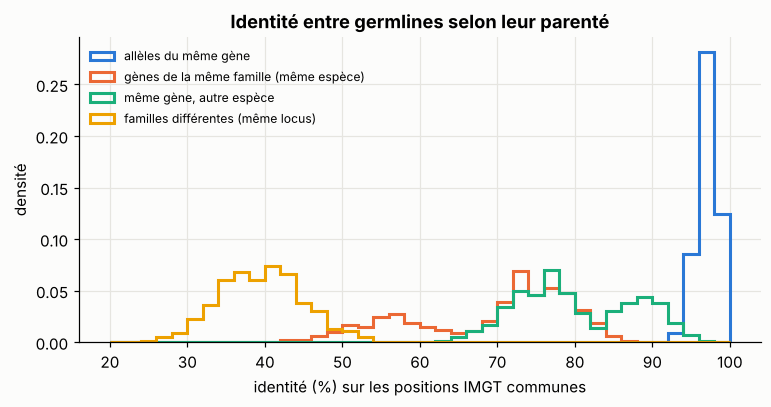

In [3]:
from protannotml.splits import encode_aligned, identity_matrix, cluster_at

X = encode_aligned([r["positions"] for r in refs])
I = identity_matrix(X)
from protannotml.imgt import allele_key
alleles = [allele_key(r["species"], r["allele"]) for r in refs]          # names are only unique within a species
meta = pd.DataFrame([{k: r[k] for k in ("allele", "gene", "family", "locus", "species")} for r in refs])

same_gene = meta.gene.to_numpy(object)[:, None] == meta.gene.to_numpy(object)[None, :]
same_fam = (meta.family.to_numpy(object)[:, None] == meta.family.to_numpy(object)[None, :]) & ~same_gene
same_sp = meta.species.to_numpy(object)[:, None] == meta.species.to_numpy(object)[None, :]
off = ~np.eye(len(refs), dtype=bool)
groups = {"allèles du même gène": same_gene & off & same_sp,
          "gènes de la même famille (même espèce)": same_fam & same_sp,
          "même gène, autre espèce": same_gene & ~same_sp,
          "familles différentes (même locus)": (meta.locus.to_numpy(object)[:, None] == meta.locus.to_numpy(object)[None, :]) & ~same_fam & ~same_gene}
fig, ax = plt.subplots(figsize=(8, 3.6))
for k, (name, mask) in enumerate(groups.items()):
    ax.hist(I[mask] * 100, bins=np.arange(20, 101, 2), histtype="step", lw=2, color=PALETTE[k], density=True, label=name)
ax.set_xlabel("identité (%) sur les positions IMGT communes"); ax.set_ylabel("densité"); ax.legend(fontsize=8, loc="upper left")
ax.set_title("Identité entre germlines selon leur parenté")
plt.show()
for name, mask in groups.items():
    print(f"{name:42s} median identity {np.median(I[mask]) * 100:5.1f}%")

## 3. Regrouper les germlines : seuils et clusters

On regroupe les allèles V par **liaison simple** (deux allèles sont dans le même groupe s'il existe une chaîne d'allèles reliés par une identité supérieure au seuil). Le seuil fixe la difficulté : à 95 %, on sépare essentiellement les gènes ; à 70 %, des familles entières. La liaison simple a un défaut connu, l'**effet de chaîne** (un grand cluster peut avaler des séquences éloignées via des intermédiaires) ; c'est pourquoi on vérifie ensuite la fuite **réelle** (section 5) plutôt que de faire confiance au seuil.

 threshold  n_clusters  largest  largest_frac
      0.60          16       37      0.101093
      0.65          17       37      0.101093
      0.70          18       37      0.101093
      0.75          33       32      0.087432
      0.80          75       28      0.076503
      0.85         130       12      0.032787
      0.90         163        8      0.021858
      0.95         192        4      0.010929
      0.99         362        2      0.005464


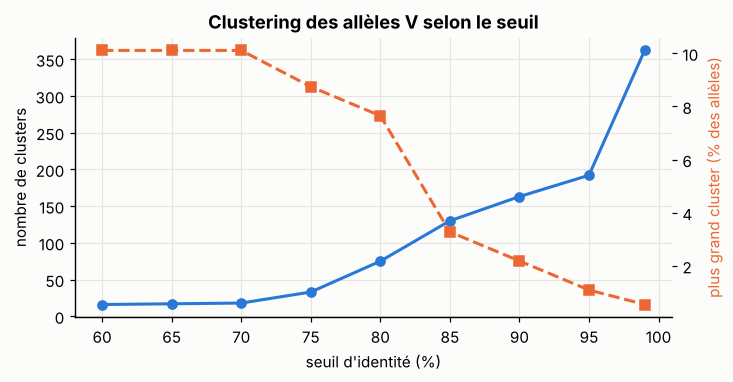

In [4]:
thresholds = [0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95, 0.99]
stats = []
for t in thresholds:
    n, lab = cluster_at(I, t)
    sizes = np.bincount(lab)
    stats.append(dict(threshold=t, n_clusters=n, largest=sizes.max(), largest_frac=sizes.max() / len(refs)))
df_t = pd.DataFrame(stats)
fig, ax = plt.subplots(figsize=(7, 3.3))
ax.plot(df_t.threshold * 100, df_t.n_clusters, "o-", label="nombre de clusters")
ax2 = ax.twinx(); ax2.plot(df_t.threshold * 100, df_t.largest_frac * 100, "s--", color=PALETTE[1], label="plus grand cluster (%)")
ax2.grid(False); ax2.set_ylabel("plus grand cluster (% des allèles)", color=PALETTE[1])
ax.set_xlabel("seuil d'identité (%)"); ax.set_ylabel("nombre de clusters"); ax.set_title("Clustering des allèles V selon le seuil")
plt.show()
print(df_t.to_string(index=False))

## 4. Quatre régimes d'évaluation

On définit une fonction générique : chaque exemple appartient aux **groupes** de ses domaines V (un scFv en a deux) ; les groupes sont tirés au hasard et répartis en entraînement / validation / test jusqu'à atteindre les proportions voulues **en nombre d'exemples**. Un exemple dont les domaines tombent dans deux côtés différents est **écarté** (et compté) : c'est le prix d'un test propre.

In [5]:
def group_split(examples, group_of_domain, fractions=(0.8, 0.1, 0.1), seed=0):
    """Assign whole groups to train/val/test. group_of_domain(domain_dict) -> hashable group id.

    Returns {"train": [...ids], "val": [...], "test": [...], "dropped": [...]}.
    """
    rng = np.random.default_rng(seed)
    ex_groups = [{group_of_domain(d) for d in ex["domains"] if d["type"] == "V"} for ex in examples]
    count = {}
    for gs in ex_groups:
        for g in gs:
            count[g] = count.get(g, 0) + 1
    order = list(count)
    rng.shuffle(order)
    total, acc, side = sum(count.values()), 0, {}
    bounds = np.cumsum(fractions) * total
    for g in order:
        side[g] = "train" if acc < bounds[0] else "val" if acc < bounds[1] else "test"
        acc += count[g]
    out = {"train": [], "val": [], "test": [], "dropped": []}
    for ex, gs in zip(examples, ex_groups):
        sides = {side[g] for g in gs}
        out[sides.pop() if len(sides) == 1 else "dropped"].append(ex["id"])
    return out

Les quatre régimes :

| Régime | Groupe | Question posée |
|---|---|---|
| **R0** aléatoire | l'exemple lui-même | référence (optimiste) : à ne **pas** publier seul |
| **R1** par allèle | l'allèle V | allèle exact jamais vu, mais ses allèles frères le sont |
| **R2** par cluster à 80 % | le cluster germline | nouveau gène / nouvelle famille |
| **R3** espèce exclue | l'espèce | nouvelle espèce (ici *Mus musculus* en test) |

In [6]:
from protannotml.splits import group_split

_, cl80 = cluster_at(I, 0.80)
cluster_of = dict(zip(alleles, cl80))
species_of_allele = dict(zip(alleles, meta.species))

rng = np.random.default_rng(0)
ids = np.array([ex["id"] for ex in examples]); rng.shuffle(ids)
n = len(ids)
splits = {
    "R0 aléatoire": {"train": list(ids[: int(0.8 * n)]), "val": list(ids[int(0.8 * n): int(0.9 * n)]), "test": list(ids[int(0.9 * n):]), "dropped": []},
    "R1 par allèle": group_split(examples, lambda d: allele_key(d["species"], d["v_allele"]), seed=0),
    "R2 cluster 80 %": group_split(examples, lambda d: int(cluster_of[allele_key(d["species"], d["v_allele"])]), seed=0),
}
held = "Mus musculus"
rest = [ex["id"] for ex in examples if ex["species"] != held]
rng.shuffle(rest)
splits["R3 espèce exclue"] = {"train": rest[: int(0.9 * len(rest))], "val": rest[int(0.9 * len(rest)):],
                              "test": [ex["id"] for ex in examples if ex["species"] == held], "dropped": []}
print(pd.DataFrame({k: {s: len(v) for s, v in sp.items()} for k, sp in splits.items()}).T.to_string())

                  train  val  test  dropped
R0 aléatoire       4800  600   600        0
R1 par allèle      4559  470   499      472
R2 cluster 80 %    4582  635   297      486
R3 espèce exclue   3555  396  2049        0


## 5. Mesurer la fuite résiduelle

Le seuil de clustering n'est qu'un moyen. Ce qui compte, c'est la **distance réelle** entre chaque exemple de test et l'entraînement. On mesure, pour chaque domaine V de test, l'identité maximale de sa germline avec les germlines utilisées dans l'entraînement, et la proportion de domaines de test dont l'**allèle exact** est vu à l'entraînement.

In [7]:
def leakage_report(examples, split, allele_index, identity):
    """Max germline identity of each test V domain to the training V alleles, and exact-allele overlap.
    allele_index maps 'species|allele' keys to rows of the identity matrix."""
    key = lambda d: f"{d['species']}|{d['v_allele']}"
    by_id = {ex["id"]: ex for ex in examples}
    train_alleles = {key(d) for i in split["train"] for d in by_id[i]["domains"] if d["type"] == "V"}
    train_idx = np.array(sorted(allele_index[a] for a in train_alleles))
    max_id, seen = [], []
    for i in split["test"]:
        for d in by_id[i]["domains"]:
            if d["type"] == "V":
                max_id.append(identity[allele_index[key(d)], train_idx].max())
                seen.append(key(d) in train_alleles)
    return np.array(max_id), np.array(seen)

          regime  test_domains exact_allele_seen median_max_identity frac_above_95
    R0 aléatoire           772              100%              100.0%          100%
   R1 par allèle           507                0%               97.8%           66%
 R2 cluster 80 %           310                0%               72.9%            0%
R3 espèce exclue          2564                0%               77.2%            0%


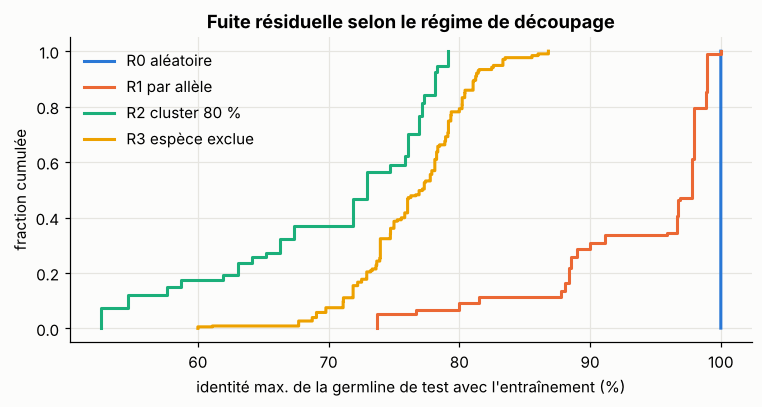

In [8]:
from protannotml.splits import leakage_report
allele_index = {a: i for i, a in enumerate(alleles)}
fig, ax = plt.subplots(figsize=(8, 3.6))
rows = []
for k, (name, sp) in enumerate(splits.items()):
    mx, seen = leakage_report(examples, sp, allele_index, I)
    xs = np.sort(mx * 100)
    ax.step(xs, np.arange(1, len(xs) + 1) / len(xs), where="post", color=PALETTE[k], label=name)
    rows.append(dict(regime=name, test_domains=len(mx), exact_allele_seen=f"{seen.mean():.0%}",
                     median_max_identity=f"{np.median(mx) * 100:.1f}%", frac_above_95=f"{(mx >= 0.95).mean():.0%}"))
ax.set_xlabel("identité max. de la germline de test avec l'entraînement (%)"); ax.set_ylabel("fraction cumulée")
ax.legend(loc="upper left"); ax.set_title("Fuite résiduelle selon le régime de découpage")
plt.show()
print(pd.DataFrame(rows).to_string(index=False))

> 🐛 **Une erreur réelle, gardée pour l'exemple.** En écrivant ce notebook, j'avais d'abord indexé les allèles par leur seul nom. Le régime R3 affichait alors 82 % d'allèles de test « déjà vus » et une identité médiane de 100 % : une fuite massive… qui n'existait pas. Le même nom d'allèle désignait trois séquences différentes chez trois espèces. Ce genre d'erreur ne se voit qu'en confrontant un résultat à ce que l'on attend (« une espèce exclue ne peut pas avoir 100 % d'identité médiane »).

Lecture : en R0, chaque domaine de test a sa germline exacte dans l'entraînement ; R1 retire l'allèle exact mais laisse ses **frères** (69 % des domaines de test restent au-dessus de 95 % d'identité ; la queue à gauche correspond aux gènes à un seul allèle). R2 et R3 déplacent toute la distribution vers la gauche : ce sont les seuls régimes qui testent une vraie généralisation. Pour un article, on rapporte **au moins** R1 (ou R0) **et** R2/R3, et on présente les performances **en fonction de l'identité maximale** (notebook 5) plutôt qu'un chiffre unique.

> ⚠️ **Chaque tâche a son régime.** En R2, les gènes de test sont **absents** de l'entraînement : un classifieur de gènes (T4) ne peut pas les prédire, par construction. Pour T4, on évalue en R0/R1 (reconnaître un gène connu malgré les mutations) et l'on mesure, en R2, la capacité à **s'abstenir** ou à proposer le gène connu le plus proche. Pour T1–T3 (domaines, régions, numérotation), R2 et R3 sont les régimes pertinents.

In [9]:
(DATA / "splits.json").write_text(json.dumps(splits))
print("saved", list(splits))

saved ['R0 aléatoire', 'R1 par allèle', 'R2 cluster 80 %', 'R3 espèce exclue']


## 6. Sur les vraies données : MMseqs2, splits temporels

Pour des centaines de milliers de séquences réarrangées, la matrice d'identité complète n'est plus possible. On utilise **MMseqs2**, qui regroupe par identité et couverture minimales :

In [ ]:
# FASTA of the V domains (one per example domain), then cluster at 80 % identity and 80 % coverage
# mmseqs easy-cluster v_domains.fasta clu80 tmp --min-seq-id 0.8 -c 0.8 --cov-mode 0
import pandas as pd
clu = pd.read_csv("clu80_cluster.tsv", sep="\t", names=["representative", "member"])
cluster_of_seq = dict(zip(clu.member, clu.representative))
split = group_split(examples, lambda d: cluster_of_seq[d["domain_id"]], seed=0)

Deux remarques pour le cas réel :

- **Clusteriser les germlines, pas seulement les séquences.** Deux anticorps aux CDR3 très différents mais issus du même gène V peuvent tomber dans des clusters MMseqs2 différents à 80 % alors qu'ils partagent 95 % de leur framework. Pour T1–T3, ce qui compte est la germline : groupe par cluster de **gène V assigné** (comme ici), ou par cluster sur la seule partie V-REGION.
- **Le split temporel** est le plus honnête pour les anticorps thérapeutiques : entraîner sur les entrées d'IMGT/mAb-DB antérieures à une date, tester sur les suivantes. Il simule exactement l'usage réel (annoter les prochains anticorps) et prend en compte la dérive des formats (bispécifiques, VHH, nouveaux échafaudages).

## 7. Récapitulatif

| Notion | À retenir |
|---|---|
| Fuite | un test proche de l'entraînement mesure la mémorisation |
| Identité IMGT | positions déjà alignées : identité = correspondances / positions co-occupées |
| Clusters | liaison simple à un seuil ; vérifier l'effet de chaîne |
| Régimes | R0/R1 (anticorps nouveaux, gènes connus), R2 (gènes nouveaux), R3 (espèce nouvelle), temporel |
| Rapport | performances en fonction de l'identité max. à l'entraînement |
| Par tâche | T4 en R0/R1 (+ abstention en R2) ; T1–T3 en R2/R3 |

### 🏋️ Exercices

1. **Effet de chaîne.** Pour le seuil de 70 %, trouve deux allèles du même cluster dont l'identité directe est inférieure à 50 %. Compare avec un clustering à liaison complète (`scipy.cluster.hierarchy`, méthode `complete`).
2. **Équilibre des loci.** Vérifie que chaque locus est représenté dans le test de R2. Sinon, adapte `group_split` pour tirer les groupes **par locus** (stratification).
3. **Vraies données.** Sur le répertoire IMGT, mesure l'identité médiane entre gènes humains et gènes de souris de la même famille. Quelle espèce serait la plus intéressante à exclure pour un test R3 réaliste ?

<details><summary>Indications</summary>

1. `np.argwhere((labels[:, None] == labels[None, :]) & (I < 0.5))` sur les labels à 70 %.
2. Appelle `group_split` séparément sur les exemples de chaque locus puis concatène ; pour les scFv (deux loci), assigne d'abord le locus lourd.
</details>